### Practice 5 - Notebook 1

# PCA with scikit-learn — Exercise 5

## Part 3: With vs. Without PCA — Rerun the Comparison with `pca_90` (8 Components)

In this exercise, we repeat the K-Means clustering comparison from Part 3 of the instructor's PCA notebook, replacing the 2-component PCA projection with `pca_90` (which retains at least 90% of the total variance using 8 principal components).

**Workflow:** load the Wine dataset, standardize the 13 features, create both the 2-component and 8-component (`pca_90`) PCA projections, run K-Means (`k=3`) on each representation, and compare the resulting Silhouette Scores and Adjusted Rand Index (ARI) values.

**Question:** Rerun the comparison with `pca_90` (8 components) instead of 2. Does the silhouette still double? Why?

## Cell 1 — Import the Required Libraries

Import the tools needed to load the dataset, standardize the features, apply PCA, run K-Means clustering, and evaluate the clusters.

In [1]:
# General tools for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset loading, feature scaling, and PCA
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Clustering algorithm and evaluation metrics
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

## Cell 2 — Load the Wine Dataset

Load the 178 wine samples and their 13 chemical features. The true class labels (`y`) are kept aside and used only at the end to compute the Adjusted Rand Index (ARI).

In [2]:
# Load the Wine dataset as a DataFrame
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())

Dataset shape: (178, 13)
Number of features: 13
Number of classes: 3


## Cell 3 — Standardize the Features

Standardize all 13 features using `StandardScaler` so that every feature has zero mean and unit variance before applying PCA and K-Means.

In [3]:
# Standardize every feature to zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (178, 13)


## Cell 4 — Apply PCA: 2 Components vs. `pca_90` (8 Components)

We transform the standardized data into two PCA representations:
- `X_pca_2`: keeps the first **2** principal components (~55.4% of total variance).
- `X_pca_90`: keeps enough components to retain at least **90%** of total variance (**8** components, ~92.0% of total variance).

In [4]:
# 2-component PCA projection (used in Part 3 of the main notebook)
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

# 90% variance PCA projection (8 components)
pca_90 = PCA(n_components=0.90)
X_pca_90 = pca_90.fit_transform(X_scaled)

print(f"2-component PCA shape:  {X_pca_2.shape} | Variance kept: {pca_2.explained_variance_ratio_.sum():.2%}")
print(f"pca_90 (8-comp) shape:  {X_pca_90.shape} | Variance kept: {pca_90.explained_variance_ratio_.sum():.2%}")

2-component PCA shape:  (178, 2) | Variance kept: 55.41%
pca_90 (8-comp) shape:  (178, 8) | Variance kept: 92.02%


## Cell 5 — Compare K-Means (`k=3`) Without PCA, With 2 Components, and With `pca_90`

Fit `KMeans(n_clusters=3, random_state=42, n_init=10)` on all three representations and compare:
- **Silhouette Score:** measures how compact and well-separated the clusters are in that specific coordinate space.
- **Adjusted Rand Index (ARI):** measures how closely the cluster assignments match the true wine classes `y`.

In [5]:
# Define the three representations to compare
representations = {
    "Without PCA (13 features)": X_scaled,
    "With PCA (2 components)": X_pca_2,
    "With pca_90 (8 components)": X_pca_90,
}

comparison_rows = []

# Fit K-Means on each representation and record evaluation metrics
for name, data in representations.items():
    km = KMeans(n_clusters=3, random_state=42, n_init=10)
    labels = km.fit_predict(data)
    
    sil = silhouette_score(data, labels)
    ari = adjusted_rand_score(y, labels)
    
    comparison_rows.append({
        "Representation": name,
        "Dimensions": data.shape[1],
        "Silhouette Score": round(sil, 4),
        "Adjusted Rand Index (ARI)": round(ari, 4),
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Representation,Dimensions,Silhouette Score,Adjusted Rand Index (ARI)
0,Without PCA (13 features),13,0.2849,0.8975
1,With PCA (2 components),2,0.5611,0.8951
2,With pca_90 (8 components),8,0.3150,0.8975


## Cell 6 — Visualize the Metric Comparison

Plot the Silhouette Score and Adjusted Rand Index (ARI) side by side across the three representations.

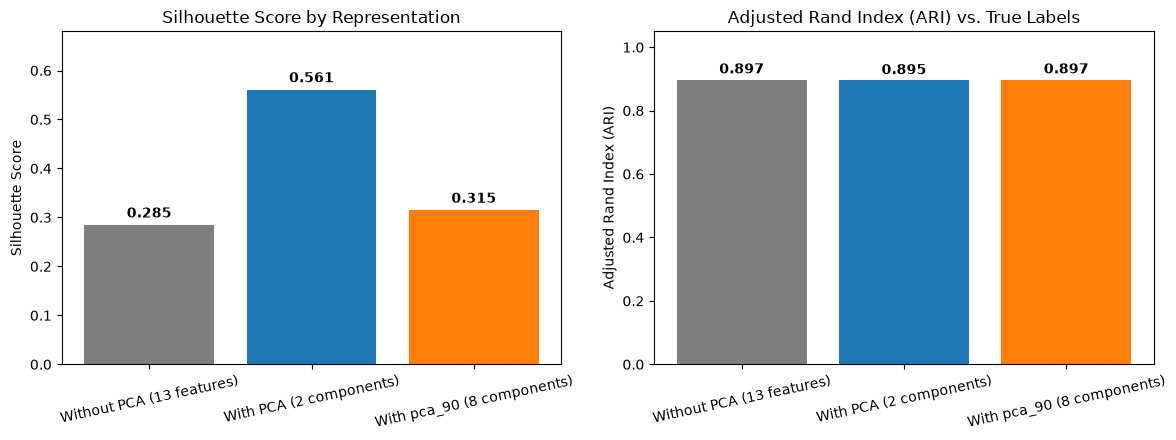

In [6]:
# Create side-by-side bar charts for Silhouette Score and ARI
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

names = comparison_df["Representation"]
colors = ["tab:gray", "tab:blue", "tab:orange"]

# Left plot: Silhouette Score
bars_sil = axes[0].bar(names, comparison_df["Silhouette Score"], color=colors)
axes[0].set_title("Silhouette Score by Representation")
axes[0].set_ylabel("Silhouette Score")
axes[0].set_ylim(0, 0.68)
axes[0].tick_params(axis="x", rotation=12)
for bar in bars_sil:
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                 f"{bar.get_height():.3f}", ha="center", fontweight="bold")

# Right plot: Adjusted Rand Index (ARI)
bars_ari = axes[1].bar(names, comparison_df["Adjusted Rand Index (ARI)"], color=colors)
axes[1].set_title("Adjusted Rand Index (ARI) vs. True Labels")
axes[1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis="x", rotation=12)
for bar in bars_ari:
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                 f"{bar.get_height():.3f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## Final Answer

**Does the silhouette score still double when using `pca_90` (8 components) instead of 2?**

**No.**
- **Without PCA (13 features):** Silhouette Score = **`0.2849`** (`ARI = 0.8975`)
- **With PCA (2 components):** Silhouette Score = **`0.5611`** (`ARI = 0.8951`) — *nearly doubles*
- **With `pca_90` (8 components):** Silhouette Score = **`0.3150`** (`ARI = 0.8975`) — *only increases slightly (+0.0301) and does not double*

**Why?**
1. **Signal vs. within-cluster spread:** In the Wine dataset, the three classes separate mainly along **PC1 and PC2** (which capture **55.41%** of the variance). Components **PC3 through PC8** add another **36.61%** of variance (reaching **92.02%** total), but that additional variance mostly reflects within-cluster spread and noise perpendicular to the 2D class-separation plane.

2. **Effect on Euclidean distances:** The Silhouette Score compares average within-cluster distance to nearest-cluster distance. Projecting down to **2 components** removes 11 dimensions of within-cluster spread, making points inside each cluster much closer together and causing the Silhouette Score to jump from `0.285` to `0.561`. When we keep **8 components (`pca_90`)**, 92% of the total variance—including most of the within-cluster spread—remains in the Euclidean distance calculations, so the Silhouette Score (`0.315`) stays very close to the 13-feature score (`0.285`).

3. **ARI and Silhouette measure different things:** The ARI values compare the clustering results with the true wine class labels; they do not directly compare the cluster assignments between the three models. The similar ARI values (about 0.895–0.898) indicate that the clustering results align similarly with the true classes. The Silhouette Score changes because distances and cluster compactness are measured in different feature spaces.